# Bank Customer Churn Analyst
Analisis Churn nasabah bank : siapa yang pergi, kenapa, dan berapa  dana yang terancam

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy.engine import URL
from sqlalchemy import create_engine
from getpass import getpass


#koneksi ke database postgre 
password = getpass("Masukkan password PostgreSQL: ")

url = URL.create(
    drivername = "postgresql+psycopg2",
    username = "postgres",
    password = password,
    host = "localhost",
    port = 5432,
    database = "bank_churn"
)

engine = create_engine(url)

df = pd.read_sql("select * from customers", engine)
print("jumlah baris dan kolom : ", df.shape)
df.head()

Masukkan password PostgreSQL:  ········


jumlah baris dan kolom :  (10000, 14)


,row_number,customer_id,surname,credit_score,geography,gender,age,tenure,balance,num_of_products,has_cr_card,is_active_member,estimated_salary,exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Temuan 1 : Churn berdasarkan negara

Baseline churn rate: 20.37%


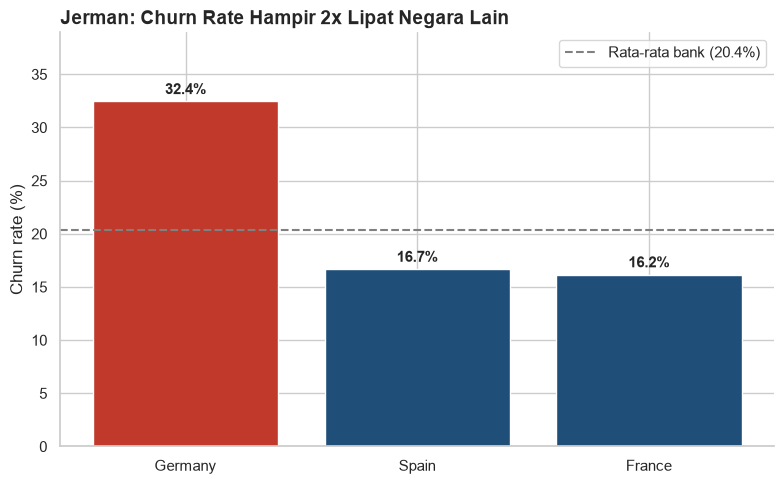

In [3]:
# Pengaturan tampilan grafik (cukup sekali di awal)
sns.set_theme(style="whitegrid")
WARNA_UTAMA = "#1f4e79"   # biru tua: kondisi normal
WARNA_BAHAYA = "#c0392b"  # merah: di atas rata-rata

# Baseline churn rate
baseline = df["exited"].mean() * 100
print(f"Baseline churn rate: {baseline:.2f}%")

# Hitung churn rate per negara
geo = (
    df.groupby("geography")
      .agg(total_nasabah=("exited", "count"),
           churn_rate=("exited", "mean"))
      .sort_values("churn_rate", ascending=False)
)
geo["churn_rate"] = geo["churn_rate"] * 100

# Warna merah untuk negara di atas rata-rata
warna = [WARNA_BAHAYA if v > baseline else WARNA_UTAMA for v in geo["churn_rate"]]

# Buat grafik
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(geo.index, geo["churn_rate"], color=warna)
ax.axhline(baseline, color="gray", linestyle="--", linewidth=1.5,
           label=f"Rata-rata bank ({baseline:.1f}%)")
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=11, fontweight="bold")

ax.set_title("Jerman: Churn Rate Hampir 2x Lipat Negara Lain",
             fontsize=14, fontweight="bold", loc="left")
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("")
ax.set_ylim(0, geo["churn_rate"].max() * 1.2)
ax.legend()
sns.despine()
plt.tight_layout()

# Simpan grafik ke folder images
plt.savefig("../images/01_churn_per_negara.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** Churn Jerman 32,4%, hampir 2x Prancis (16,2%) dan Spanyol (16,7%). Jerman hanya ±25% nasabah, tetapi menyumbang ±53% saldo yang hilang.

## Temuan 2 : Churn Berdasarkan kelompok umur


               total_nasabah  churn_rate
kelompok_umur                           
18-29                   1641    7.556368
30-39                   4346   10.883571
40-49                   2618   30.786860
50-59                    869   56.041427
60+                      526   27.946768


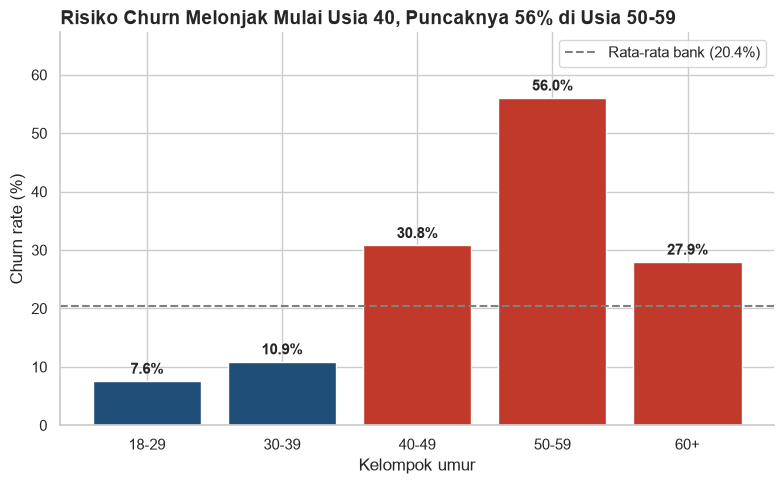

In [4]:
# Kelompokkan umur (binning), sama seperti CASE WHEN di SQL
bins = [0, 29, 39, 49, 59, 120]
labels = ["18-29", "30-39", "40-49", "50-59", "60+"]
df["kelompok_umur"] = pd.cut(df["age"], bins=bins, labels=labels)

# Hitung churn rate per kelompok umur
umur = (
    df.groupby("kelompok_umur", observed=True)
      .agg(total_nasabah=("exited", "count"),
           churn_rate=("exited", "mean"))
)
umur["churn_rate"] = umur["churn_rate"] * 100
print(umur)

# Warna merah untuk kelompok di atas rata-rata
warna = [WARNA_BAHAYA if v > baseline else WARNA_UTAMA for v in umur["churn_rate"]]

# Buat grafik
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(umur.index.astype(str), umur["churn_rate"], color=warna)
ax.axhline(baseline, color="gray", linestyle="--", linewidth=1.5,
           label=f"Rata-rata bank ({baseline:.1f}%)")
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=11, fontweight="bold")

ax.set_title("Risiko Churn Melonjak Mulai Usia 40, Puncaknya 56% di Usia 50-59",
             fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel("Kelompok umur")
ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, umur["churn_rate"].max() * 1.2)
ax.legend()
sns.despine()
plt.tight_layout()

plt.savefig("../images/02_churn_per_umur.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** Risiko churn melonjak mulai usia 40 dan memuncak di usia 50–59 (56,0%). Usia 40–59 hanya 35% nasabah, tetapi menyumbang 63% churn.

## Temuan 3: Churn Berdasarkan Jumlah Produk

                 total_nasabah  churn_rate
num_of_products                           
1                         5084   27.714398
2                         4590    7.581699
3                          266   82.706767
4                           60  100.000000


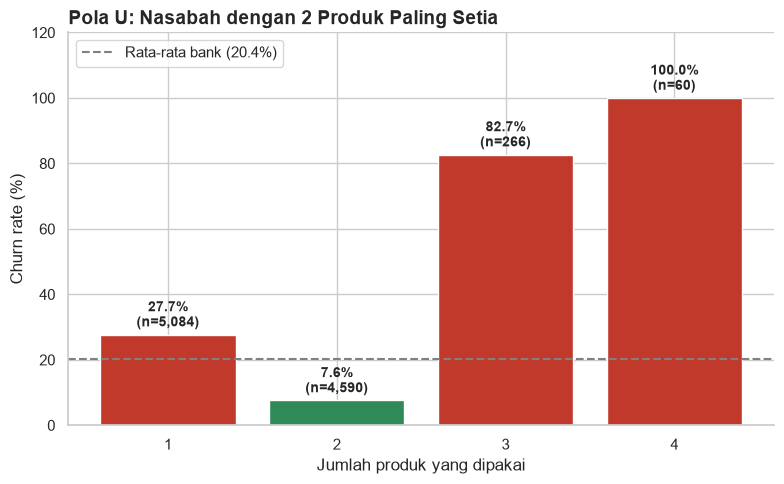

In [5]:
# Hitung churn rate per jumlah produk
produk = (
    df.groupby("num_of_products")
      .agg(total_nasabah=("exited", "count"),
           churn_rate=("exited", "mean"))
)
produk["churn_rate"] = produk["churn_rate"] * 100
print(produk)

# Warna: hijau untuk titik ideal (2 produk), merah untuk di atas rata-rata
WARNA_AMAN = "#2e8b57"
warna = []
for jumlah, rate in zip(produk.index, produk["churn_rate"]):
    if jumlah == 2:
        warna.append(WARNA_AMAN)
    elif rate > baseline:
        warna.append(WARNA_BAHAYA)
    else:
        warna.append(WARNA_UTAMA)

# Label batang: churn rate + jumlah nasabah (n)
label = [f"{rate:.1f}%\n(n={n:,})" for rate, n in zip(produk["churn_rate"], produk["total_nasabah"])]

# Buat grafik
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(produk.index.astype(str), produk["churn_rate"], color=warna)
ax.axhline(baseline, color="gray", linestyle="--", linewidth=1.5,
           label=f"Rata-rata bank ({baseline:.1f}%)")
ax.bar_label(bars, labels=label, padding=3, fontsize=10, fontweight="bold")

ax.set_title("Pola U: Nasabah dengan 2 Produk Paling Setia",
             fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel("Jumlah produk yang dipakai")
ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, 120)
ax.legend(loc="upper left")
sns.despine()
plt.tight_layout()

plt.savefig("../images/03_churn_per_produk.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** Polanya membentuk huruf U. Nasabah dengan 2 produk paling setia (7,6%), sedangkan nasabah 1 produk menyumbang 69% churn. Kelompok 3–4 produk churn-nya sangat tinggi, tetapi sampelnya kecil (n=326).

## Temuan 4: Churn Berdasarkan Status Keaktifan

                  total_nasabah  churn_rate  saldo_bertahan
status_keaktifan                                           
Tidak Aktif                4849   26.850897    2.555572e+08
Aktif                      5151   14.269074    3.237136e+08


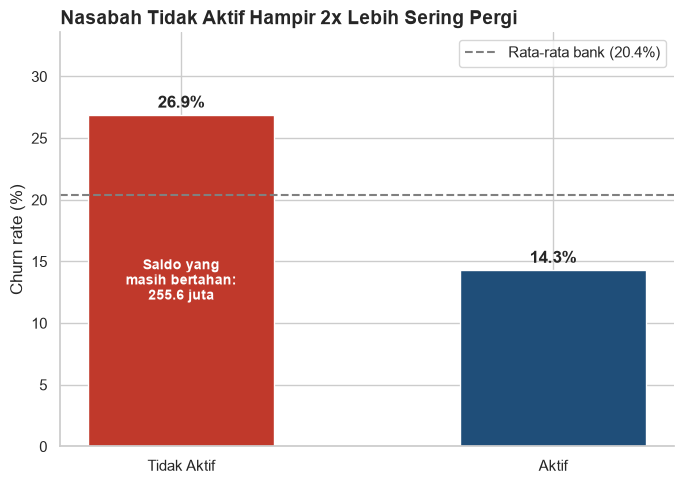

In [6]:
# Label status keaktifan
df["status_keaktifan"] = df["is_active_member"].map({1: "Aktif", 0: "Tidak Aktif"})

# Hitung churn rate dan saldo nasabah yang masih bertahan
aktif = (
    df.groupby("status_keaktifan")
      .agg(total_nasabah=("exited", "count"),
           churn_rate=("exited", "mean"))
)
aktif["churn_rate"] = aktif["churn_rate"] * 100
aktif["saldo_bertahan"] = df[df["exited"] == 0].groupby("status_keaktifan")["balance"].sum()
aktif = aktif.sort_values("churn_rate", ascending=False)
print(aktif)

# Warna
warna = [WARNA_BAHAYA if v > baseline else WARNA_UTAMA for v in aktif["churn_rate"]]

# Buat grafik
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(aktif.index, aktif["churn_rate"], color=warna, width=0.5)
ax.axhline(baseline, color="gray", linestyle="--", linewidth=1.5,
           label=f"Rata-rata bank ({baseline:.1f}%)")
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=12, fontweight="bold")

# Catatan saldo terancam
saldo_tidak_aktif = aktif.loc["Tidak Aktif", "saldo_bertahan"] / 1_000_000
ax.text(0, aktif.loc["Tidak Aktif", "churn_rate"] / 2,
        f"Saldo yang\nmasih bertahan:\n{saldo_tidak_aktif:.1f} juta",
        ha="center", va="center", color="white", fontsize=10, fontweight="bold")

ax.set_title("Nasabah Tidak Aktif Hampir 2x Lebih Sering Pergi",
             fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel("")
ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, aktif["churn_rate"].max() * 1.25)
ax.legend()
sns.despine()
plt.tight_layout()

plt.savefig("../images/04_churn_per_keaktifan.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** Nasabah tidak aktif pergi hampir 2x lebih sering (26,9% vs 14,3%). Masih ada 3.547 nasabah tidak aktif yang bertahan dengan saldo 255,6 juta.

## Temuan 5: Skor Risiko Churn & Saldo yang Terancam
Skor risiko dibuat dari 4 faktor yang terbukti dalam analisis sebelumnya (masing-masing bernilai 1 poin):
1. Tinggal di Jerman
2. Berusia 40-59 tahun
3. Memakai jumlah produk selain 2
4. Tidak aktif

             total_nasabah  churn_rate
skor_risiko                           
0                     1341    2.833706
1                     3434    7.425743
2                     3246   21.010474
3                     1587   48.456207
4                      392   74.744898 

               nasabah         saldo  saldo_juta
segmen_risiko                                   
Risiko Tinggi      917  1.015875e+08  101.587450
Risiko Sedang     2564  2.374161e+08  237.416149
Risiko Rendah     4482  2.402672e+08  240.267199

Total saldo nasabah bertahan: 579,270,798.25


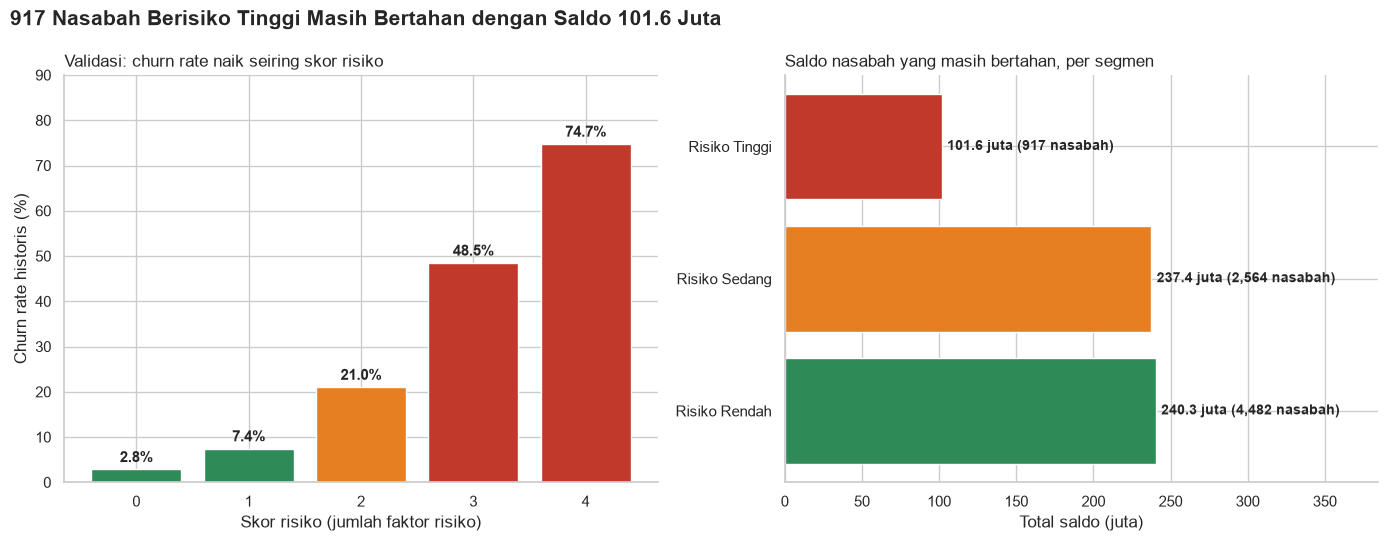

In [7]:
# Hitung skor risiko (0-4), sama seperti CTE di SQL
df["skor_risiko"] = (
      (df["geography"] == "Germany").astype(int)
    + df["age"].between(40, 59).astype(int)
    + (df["num_of_products"] != 2).astype(int)
    + (df["is_active_member"] == 0).astype(int)
)

# Kelompokkan skor menjadi segmen
def tentukan_segmen(skor):
    if skor >= 3:
        return "Risiko Tinggi"
    elif skor == 2:
        return "Risiko Sedang"
    else:
        return "Risiko Rendah"

df["segmen_risiko"] = df["skor_risiko"].apply(tentukan_segmen)

# Tabel 1: validasi skor (churn rate historis per skor)
skor = (
    df.groupby("skor_risiko")
      .agg(total_nasabah=("exited", "count"),
           churn_rate=("exited", "mean"))
)
skor["churn_rate"] = skor["churn_rate"] * 100
print(skor, "\n")

# Tabel 2: nasabah yang MASIH BERTAHAN per segmen
bertahan = df[df["exited"] == 0]
urutan = ["Risiko Tinggi", "Risiko Sedang", "Risiko Rendah"]
segmen = (
    bertahan.groupby("segmen_risiko")
            .agg(nasabah=("customer_id", "count"),
                 saldo=("balance", "sum"))
            .reindex(urutan)
)
segmen["saldo_juta"] = segmen["saldo"] / 1_000_000
print(segmen)
print(f"\nTotal saldo nasabah bertahan: {segmen['saldo'].sum():,.2f}")

# ===== GRAFIK =====
WARNA_SEDANG = "#e67e22"
warna_segmen = {"Risiko Tinggi": WARNA_BAHAYA, "Risiko Sedang": WARNA_SEDANG, "Risiko Rendah": WARNA_AMAN}
warna_skor = [warna_segmen[tentukan_segmen(s)] for s in skor.index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Kiri: churn rate naik seiring skor
bars1 = ax1.bar(skor.index.astype(str), skor["churn_rate"], color=warna_skor)
ax1.bar_label(bars1, fmt="%.1f%%", padding=3, fontsize=11, fontweight="bold")
ax1.set_title("Validasi: churn rate naik seiring skor risiko", fontsize=12, loc="left")
ax1.set_xlabel("Skor risiko (jumlah faktor risiko)")
ax1.set_ylabel("Churn rate historis (%)")
ax1.set_ylim(0, 90)

# Kanan: saldo terancam per segmen
bars2 = ax2.barh(segmen.index, segmen["saldo_juta"],
                 color=[warna_segmen[s] for s in segmen.index])
label2 = [f"{s:.1f} juta ({n:,} nasabah)" for s, n in zip(segmen["saldo_juta"], segmen["nasabah"])]
ax2.bar_label(bars2, labels=label2, padding=4, fontsize=10, fontweight="bold")
ax2.invert_yaxis()
ax2.set_title("Saldo nasabah yang masih bertahan, per segmen", fontsize=12, loc="left")
ax2.set_xlabel("Total saldo (juta)")
ax2.set_xlim(0, segmen["saldo_juta"].max() * 1.6)

# Judul utama: dihitung otomatis dari data
tinggi = segmen.loc["Risiko Tinggi"]
fig.suptitle(
    f"{int(tinggi['nasabah']):,} Nasabah Berisiko Tinggi Masih Bertahan "
    f"dengan Saldo {tinggi['saldo_juta']:.1f} Juta",
    fontsize=15, fontweight="bold", x=0.01, ha="left"
)
sns.despine()
plt.tight_layout()

plt.savefig("../images/05_skor_risiko_saldo_terancam.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** Churn naik konsisten dari 2,8% (skor 0) ke 74,7% (skor 4), sehingga skor ini valid sebagai alat prioritas. 917 nasabah berisiko tinggi masih bertahan dengan saldo 101,6 juta.

## Ekspor Data untuk Dashboard

In [8]:
# Pilih kolom yang dibutuhkan dashboard (tanpa nama nasabah)
kolom = [
    "customer_id", "geography", "gender", "age", "kelompok_umur",
    "tenure", "balance", "num_of_products", "status_keaktifan",
    "exited", "skor_risiko", "segmen_risiko"
]
df_dashboard = df[kolom].copy()
df_dashboard["status_churn"] = df_dashboard["exited"].map({1: "Churn", 0: "Bertahan"})

# Simpan ke CSV
df_dashboard.to_csv("../data/churn_dashboard.csv", index=False)

print("Data berhasil diekspor:", df_dashboard.shape)
df_dashboard.head()

Data berhasil diekspor: (10000, 13)


,customer_id,geography,gender,age,kelompok_umur,tenure,balance,num_of_products,status_keaktifan,exited,skor_risiko,segmen_risiko,status_churn
0,15634602,France,Female,42,40-49,2,0.00,1,Aktif,1,2,Risiko Sedang,Churn
1,15647311,Spain,Female,41,40-49,1,83807.86,1,Aktif,0,2,Risiko Sedang,Bertahan
2,15619304,France,Female,42,40-49,8,159660.80,3,Tidak Aktif,1,3,Risiko Tinggi,Churn
3,15701354,France,Female,39,30-39,1,0.00,2,Tidak Aktif,0,1,Risiko Rendah,Bertahan
4,15737888,Spain,Female,43,40-49,2,125510.82,1,Aktif,0,2,Risiko Sedang,Bertahan
